# Лабораторная работа 4
Самарин НА КИ25-04-3М

## 1. Инициализация

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
import os
import sys
import re
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["HADOOP_HOME"] = "C:\\hadoop"
os.environ["hadoop.home.dir"] = "C:\\hadoop"
os.environ["PATH"] += os.pathsep + "C:\\hadoop\\bin"

spark = (
    SparkSession.builder
    .appName("Olist_LR4_Data_Preprocessing")
    .master("local[*]")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.shuffle.partitions", "8")
    .config("spark.ui.enabled", "false")
    .config("spark.pyspark.python", sys.executable)
    .config("spark.pyspark.driver.python", sys.executable)
    .config("spark.python.worker.faulthandler.enabled", "true")
    .config("spark.sql.execution.pyspark.udf.faulthandler.enabled", "true")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

# Проверяем что spark работает
print("Spark version:", spark.version)
print("Master:", spark.sparkContext.master)
print("Application:", spark.sparkContext.appName)
print("Spark UI:", spark.sparkContext.uiWebUrl)
spark.range(3).show()

Spark version: 4.3.0
Master: local[*]
Application: Olist_LR4_Data_Preprocessing
Spark UI: None
+---+
| id|
+---+
|  0|
|  1|
|  2|
+---+



In [2]:
LR3_OUTPUT = "../data/output"

DATA_PATHS = {
    "orders": f"{LR3_OUTPUT}/orders_clean",
    "order_items": f"{LR3_OUTPUT}/order_items_clean",
    "products": f"{LR3_OUTPUT}/products_clean",
    "customers": f"{LR3_OUTPUT}/customers_clean",
    "reviews": f"{LR3_OUTPUT}/reviews_clean"
}

OUTPUT_PATH = "../data/output/LR4"

for name, path in DATA_PATHS.items():
    print(f"{name}: {path} | exists: {os.path.exists(path)}")

orders: ../data/output/orders_clean | exists: True
order_items: ../data/output/order_items_clean | exists: True
products: ../data/output/products_clean | exists: True
customers: ../data/output/customers_clean | exists: True
reviews: ../data/output/reviews_clean | exists: True


## 2. Импорт очищенных данных

Очищенные таблицы из ЛР 3 загружаются из Parquet с помощью Spark.

In [3]:
orders = spark.read.parquet(DATA_PATHS["orders"])
order_items = spark.read.parquet(DATA_PATHS["order_items"])
products = spark.read.parquet(DATA_PATHS["products"])
customers = spark.read.parquet(DATA_PATHS["customers"])
reviews = spark.read.parquet(DATA_PATHS["reviews"])

datasets = {
    "orders_clean": orders,
    "order_items_clean": order_items,
    "products_clean": products,
    "customers_clean": customers,
    "reviews_clean": reviews
}

for name, df in datasets.items():
    print(f"\n{name}")
    print("Количество строк:", df.count())
    print("Количество столбцов:", len(df.columns))
    df.printSchema()


orders_clean
Количество строк: 99441
Количество столбцов: 8
root
 |-- order_id: string (nullable = true)
 |-- customer_id: string (nullable = true)
 |-- order_status: string (nullable = true)
 |-- order_purchase_timestamp: timestamp (nullable = true)
 |-- order_approved_at: timestamp (nullable = true)
 |-- order_delivered_carrier_date: timestamp (nullable = true)
 |-- order_delivered_customer_date: timestamp (nullable = true)
 |-- order_estimated_delivery_date: timestamp (nullable = true)


order_items_clean
Количество строк: 112650
Количество столбцов: 7
root
 |-- order_id: string (nullable = true)
 |-- order_item_id: integer (nullable = true)
 |-- product_id: string (nullable = true)
 |-- seller_id: string (nullable = true)
 |-- shipping_limit_date: timestamp (nullable = true)
 |-- price: double (nullable = true)
 |-- freight_value: double (nullable = true)


products_clean
Количество строк: 32951
Количество столбцов: 9
root
 |-- product_id: string (nullable = true)
 |-- product_cat

In [4]:
orders.show(5, truncate=False)
order_items.show(5, truncate=False)
products.show(5, truncate=False)
customers.show(5, truncate=False)
reviews.show(5, truncate=False)

+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+
|0006ec9db01a64e59a68b2c340bf65a7|5d178120c29c61748ea95bac23cb8f25|delivered   |2018-07-24 17:04:17     |2018-07-24 17:24:20|2018-07-25 11:02:00         |2018-07-31 01:04:15          |2018-08-22 00:00:00          |
|000aed2e25dbad2f9ddb70584c5a2ded|fff5169e583fd07fac9fec88962f189d|delivered   |2018-05-11 20:33:38     |2018-05-11 20:57:03|2018-05-16 14:2

## 3. Аналитическая обработка структурированных данных

Структурированные данные представлены таблицами заказов и товарных позиций. Таблицы объединяются по идентификатору заказа. На основе объединённых данных рассчитываются количество заказов, выручка и стоимость доставки по месяцам.

In [5]:
orders = orders.withColumn(
    "order_purchase_timestamp",
    F.to_timestamp("order_purchase_timestamp")
)

orders_items = orders.join(
    order_items,
    on="order_id",
    how="inner"
)

print("Количество строк объединённой таблицы:", orders_items.count())
orders_items.show(5, truncate=False)

Количество строк объединённой таблицы: 112650
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+-------------+--------------------------------+--------------------------------+-------------------+-----+-------------+
|order_id                        |customer_id                     |order_status|order_purchase_timestamp|order_approved_at  |order_delivered_carrier_date|order_delivered_customer_date|order_estimated_delivery_date|order_item_id|product_id                      |seller_id                       |shipping_limit_date|price|freight_value|
+--------------------------------+--------------------------------+------------+------------------------+-------------------+----------------------------+-----------------------------+-----------------------------+-------------+--------------------------------+-----------------------

### 3.1. Динамика продаж по месяцам

Выполняется группировка заказов по месяцам. Рассчитываются количество уникальных заказов, выручка от продажи товаров и суммарная стоимость доставки.

In [6]:
monthly_sales = (
    orders_items
    .withColumn("month", F.date_format("order_purchase_timestamp", "yyyy-MM"))
    .groupBy("month")
    .agg(
        F.countDistinct("order_id").alias("orders_count"),
        F.sum("price").alias("revenue"),
        F.sum("freight_value").alias("freight_total")
    )
    .orderBy("month")
)

monthly_sales.show(30, truncate=False)

+-------+------------+------------------+------------------+
|month  |orders_count|revenue           |freight_total     |
+-------+------------+------------------+------------------+
|2016-09|3           |267.36            |87.39             |
|2016-10|308         |49507.65999999996 |7301.1799999999985|
|2016-12|1           |10.9              |8.72              |
|2017-01|789         |120312.87000000029|16875.62          |
|2017-02|1733        |247303.02000000043|38977.60000000003 |
|2017-03|2641        |374344.2999999998 |57704.28999999998 |
|2017-04|2391        |359927.22999999975|52495.00999999999 |
|2017-05|3660        |506071.13999999844|80119.81          |
|2017-06|3217        |433038.59999999905|69924.44000000009 |
|2017-07|3969        |498031.47999999835|86940.14          |
|2017-08|4293        |573971.6799999967 |94232.91999999993 |
|2017-09|4243        |624401.6899999955 |95997.21999999986 |
|2017-10|4568        |664219.4299999939 |105092.93999999978|
|2017-11|7451        |10

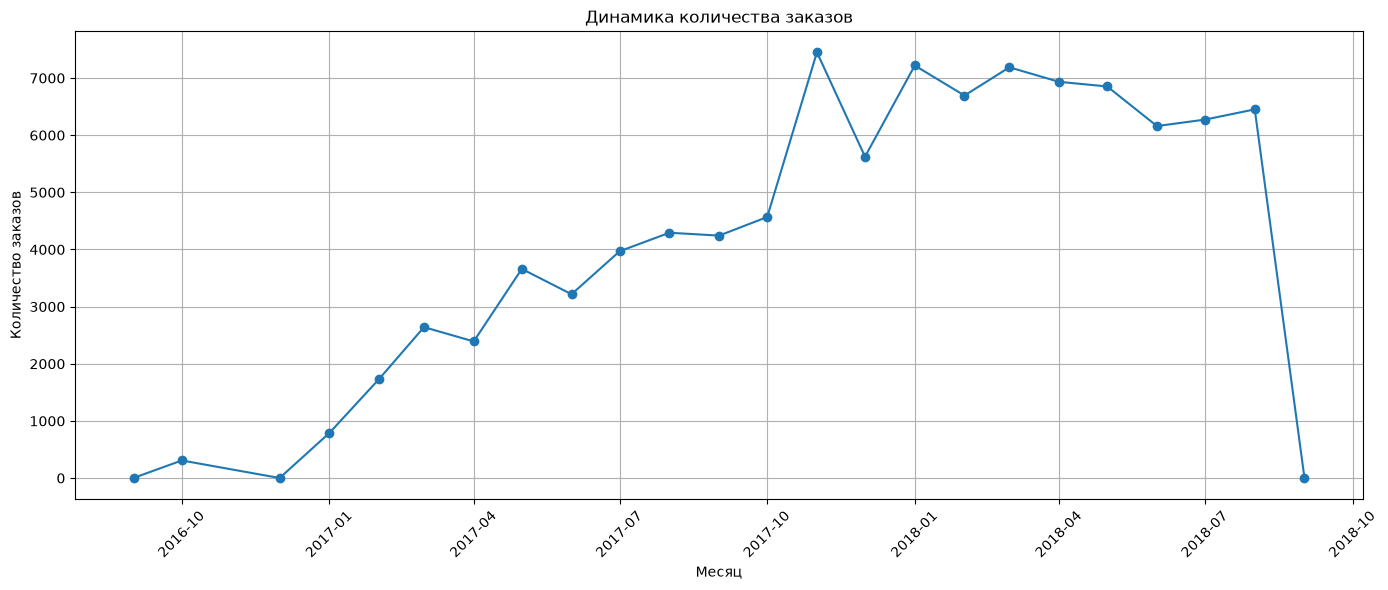

In [7]:
sales_pd = monthly_sales.toPandas()

sales_pd["month"] = pd.to_datetime(
    sales_pd["month"]
)

plt.figure(figsize=(14, 6))

plt.plot(
    sales_pd["month"],
    sales_pd["orders_count"],
    marker="o"
)

plt.title("Динамика количества заказов")
plt.xlabel("Месяц")
plt.ylabel("Количество заказов")
plt.grid(True)
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

### 3.2. Анализ продаж по категориям товаров

Таблица товарных позиций объединяется с очищенной таблицей товаров. Если в таблице товаров присутствует английское название категории, используется оно; иначе используется исходное название категории.

In [8]:
# Определяем столбец категории в очищенной таблице товаров
category_col = (
    "product_category_name_english"
    if "product_category_name_english" in products.columns
    else "product_category_name"
)

category_sales = (
    order_items
    .join(products, on="product_id", how="left")
    .groupBy(category_col)
    .agg(
        F.count("*").alias("items_sold"),
        F.sum("price").alias("revenue")
    )
    .orderBy(F.desc("revenue"))
)

category_sales.show(20, truncate=False)

+----------------------+----------+------------------+
|product_category_name |items_sold|revenue           |
+----------------------+----------+------------------+
|beleza_saude          |9670      |1258681.3399999929|
|relogios_presentes    |5991      |1205005.6799999967|
|cama_mesa_banho       |11115     |1036988.6799999906|
|esporte_lazer         |8641      |988048.969999996  |
|informatica_acessorios|7827      |911954.3199999973 |
|moveis_decoracao      |8334      |729762.4899999977 |
|cool_stuff            |3796      |635290.8500000003 |
|utilidades_domesticas |6964      |632248.6600000004 |
|automotivo            |4235      |592720.1100000006 |
|ferramentas_jardim    |4347      |485256.4600000017 |
|brinquedos            |4117      |483946.60000000114|
|bebes                 |3065      |411764.890000001  |
|perfumaria            |3419      |399124.8700000008 |
|telefonia             |4545      |323667.5300000011 |
|moveis_escritorio     |1691      |273960.7000000005 |
|papelaria

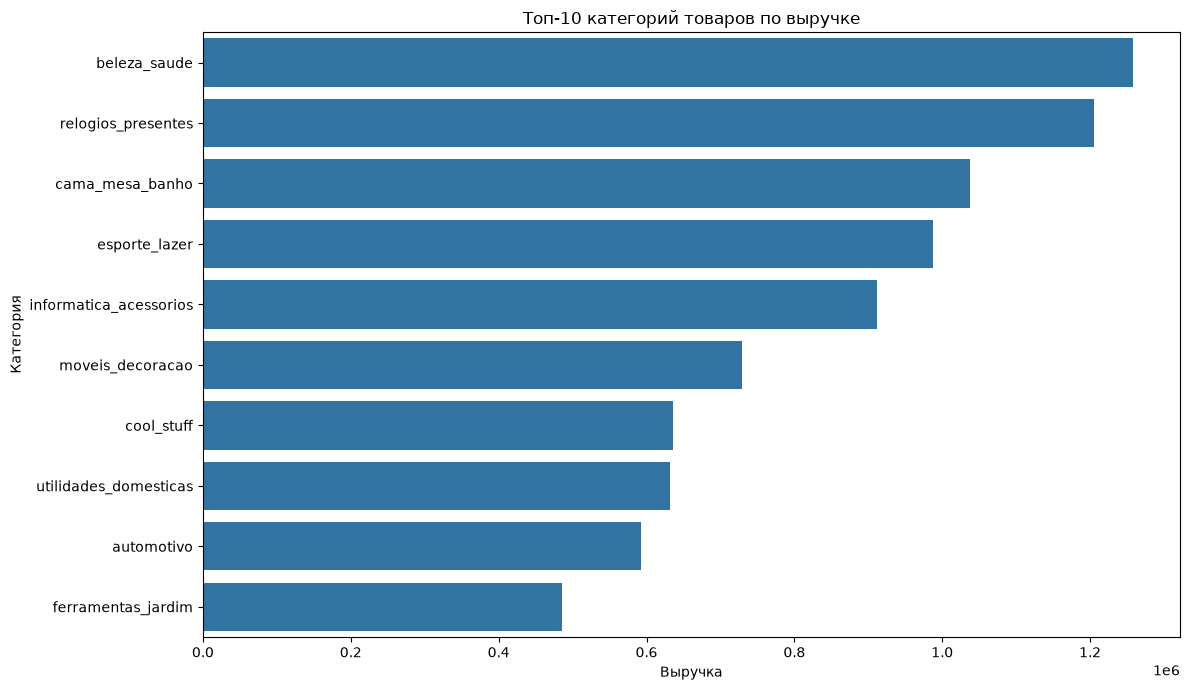

In [9]:
category_pd = category_sales.toPandas()

category_top10 = (
    category_pd
    .head(10)
)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=category_top10,
    x="revenue",
    y="product_category_name"
)

plt.title("Топ-10 категорий товаров по выручке")
plt.xlabel("Выручка")
plt.ylabel("Категория")

plt.tight_layout()
plt.show()

### 3.3. Анализ продаж по штатам

Таблица заказов объединяется с очищенной таблицей покупателей. Рассчитывается количество уникальных заказов в каждом штате.

In [10]:
orders_by_state = (
    orders
    .join(customers, on="customer_id", how="left")
    .groupBy("customer_state")
    .agg(F.countDistinct("order_id").alias("orders_count"))
    .orderBy(F.desc("orders_count"))
)

orders_by_state.show(20, truncate=False)

+--------------+------------+
|customer_state|orders_count|
+--------------+------------+
|SP            |41746       |
|RJ            |12852       |
|MG            |11635       |
|RS            |5466        |
|PR            |5045        |
|SC            |3637        |
|BA            |3380        |
|DF            |2140        |
|ES            |2033        |
|GO            |2020        |
|PE            |1652        |
|CE            |1336        |
|PA            |975         |
|MT            |907         |
|MA            |747         |
|MS            |715         |
|PB            |536         |
|PI            |495         |
|RN            |485         |
|AL            |413         |
+--------------+------------+
only showing top 20 rows


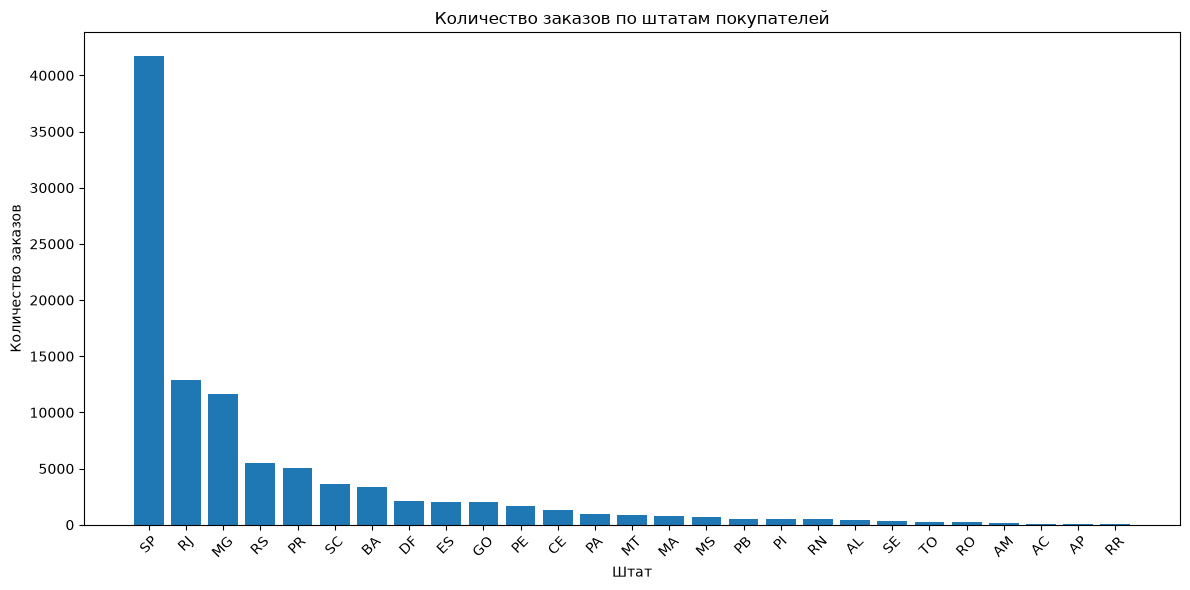

In [11]:
state_data = orders_by_state.toPandas()

plt.figure(figsize=(12, 6))
plt.bar(state_data["customer_state"], state_data["orders_count"])
plt.title("Количество заказов по штатам покупателей")
plt.xlabel("Штат")
plt.ylabel("Количество заказов")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. Обработка неструктурированных данных. MapReduce

Текстовые комментарии покупателей в таблице отзывов относятся к неструктурированным данным.

Для MapReduce используются очищенные отзывы из ЛР 3. Выбираются непустые текстовые сообщения, после чего они преобразуются в набор слов.

In [12]:
text_col = "review_comment_message"

reviews_text = (
    reviews
    .select(text_col)
    .filter(F.col(text_col).isNotNull())
    .filter(F.trim(F.col(text_col)) != "")
)

print("Количество отзывов с текстом:", reviews_text.count())
reviews_text.show(10, truncate=False)

Количество отзывов с текстом: 40659
+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|review_comment_message                                                                                                                                                                                 |
+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+
|Chegou bem antes do prazo e o material de muito boa qualidade!                                                                                                                                         |
|Fiquei muito satisfeita.                                                                                                                                   

MapReduce включает два основных этапа. На этапе Map текст преобразуется в пары (слово, 1). На этапе Reduce одинаковые слова объединяются, а значения суммируются.

Подсчитывается частота употребления слов в отзывах покупателей. Удаляются знаки препинания, текст приводится к нижнему регистру, слова длиной <3 исключаются.

In [17]:
text_rdd = reviews_text.select(text_col).rdd.map(lambda row: row[0])

def map_words(text):
    if text is None:
        return []
    text = text.lower()
    text = re.sub(r"[^a-zA-ZÀ-ÿ\s]", " ", text)
    words = text.split()
    return [(word, 1) for word in words if len(word) > 2]

mapped_rdd = text_rdd.flatMap(map_words)

print("Примеры результатов Map:")
print(mapped_rdd.take(20))

Примеры результатов Map:
[('chegou', 1), ('bem', 1), ('antes', 1), ('prazo', 1), ('material', 1), ('muito', 1), ('boa', 1), ('qualidade', 1), ('fiquei', 1), ('muito', 1), ('satisfeita', 1), ('produto', 1), ('tinha', 1), ('loja', 1), ('receber', 1), ('produto', 1), ('gostei', 1), ('produto', 1), ('chegou', 1), ('prazo', 1)]


Функция reduceByKey объединяет пары с одинаковыми ключами и суммирует их значения. Получается список слов с количеством их появлений в текстовых отзывах.

In [18]:
word_counts = mapped_rdd.reduceByKey(lambda a, b: a + b)

word_counts_sorted = word_counts.sortBy(
    lambda x: x[1],
    ascending=False
)

print("Наиболее часто встречающиеся слова:")
word_counts_sorted.take(20)

Наиболее часто встречающиеся слова:


[('produto', 18290),
 ('não', 10693),
 ('prazo', 8431),
 ('que', 8243),
 ('muito', 7883),
 ('entrega', 6484),
 ('com', 5730),
 ('antes', 5605),
 ('chegou', 5523),
 ('recebi', 5211),
 ('bom', 4573),
 ('foi', 4518),
 ('recomendo', 4314),
 ('entregue', 3753),
 ('veio', 3250),
 ('para', 3138),
 ('bem', 3103),
 ('mas', 2965),
 ('qualidade', 2757),
 ('comprei', 2721)]

Результаты RDD преобразуются в Spark DataFrame для удобного просмотра, дальнейшей аналитики и экспорта.

In [19]:
word_counts_df = spark.createDataFrame(
    word_counts_sorted,
    ["word", "frequency"]
)

word_counts_df.show(20, truncate=False)

+---------+---------+
|word     |frequency|
+---------+---------+
|produto  |18290    |
|não      |10693    |
|prazo    |8431     |
|que      |8243     |
|muito    |7883     |
|entrega  |6484     |
|com      |5730     |
|antes    |5605     |
|chegou   |5523     |
|recebi   |5211     |
|bom      |4573     |
|foi      |4518     |
|recomendo|4314     |
|entregue |3753     |
|veio     |3250     |
|para     |3138     |
|bem      |3103     |
|mas      |2965     |
|qualidade|2757     |
|comprei  |2721     |
+---------+---------+
only showing top 20 rows


Для визуального анализа строится диаграмма 20 наиболее часто встречающихся слов.

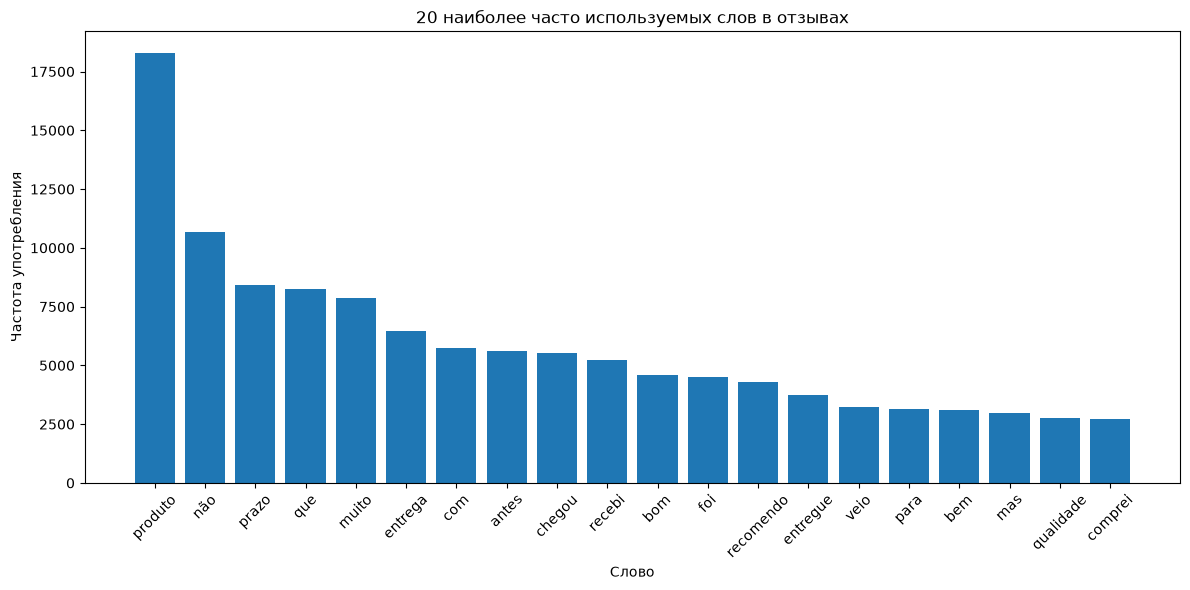

In [20]:
top_words = word_counts_df.limit(20).toPandas()

plt.figure(figsize=(12, 6))
plt.bar(top_words["word"], top_words["frequency"])
plt.title("20 наиболее часто используемых слов в отзывах")
plt.xlabel("Слово")
plt.ylabel("Частота употребления")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 5. Экспорт результатов обработки

Результаты аналитической обработки сохраняются в CSV и Parquet. CSV предназначен для обмена данными и просмотра в табличных редакторах. Parquet используется для эффективного хранения и последующей аналитической обработки.

In [21]:
os.makedirs(OUTPUT_PATH, exist_ok=True)

# Экспорт в CSV
monthly_sales.coalesce(1).write.mode("overwrite").option("header", True).csv(
    f"{OUTPUT_PATH}/monthly_sales_csv"
)

category_sales.coalesce(1).write.mode("overwrite").option("header", True).csv(
    f"{OUTPUT_PATH}/category_sales_csv"
)

word_counts_df.coalesce(1).write.mode("overwrite").option("header", True).csv(
    f"{OUTPUT_PATH}/word_counts_csv"
)

orders_by_state.coalesce(1).write.mode("overwrite").option("header", True).csv(
    f"{OUTPUT_PATH}/orders_by_state_csv"
)

print("Экспорт в CSV выполнен")

Экспорт в CSV выполнен


In [22]:
# Экспорт в Parquet
monthly_sales.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/monthly_sales_parquet"
)

category_sales.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/category_sales_parquet"
)

word_counts_df.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/word_counts_parquet"
)

orders_by_state.write.mode("overwrite").parquet(
    f"{OUTPUT_PATH}/orders_by_state_parquet"
)

print("Экспорт в Parquet выполнен")

Экспорт в Parquet выполнен


## 6. Вывод

В ходе лабораторной работы было разработано Spark-приложение для обработки и анализа очищенных данных электронной коммерции, подготовленных в ЛР 3.

Выполнен импорт данных из формата Parquet, аналитическая обработка структурированных данных, объединение таблиц заказов и товарных позиций, расчёт показателей продаж, анализ категорий товаров, анализ продаж по штатам.

Для обработки неструктурированных текстовых отзывов реализован алгоритм MapReduce, позволяющий подсчитать частоту употребления слов.

Результаты обработки экспортированы в форматы CSV и Parquet. Выполнена проверка повторного импорта сохранённых данных.